# Komparasi roll, pitch, yaw — `261118132908`

Berkas PLG1 firmware 2.4.1, 4595 rekaman, sekitar 45 detik. Di sesi ini dua load cell dibebani bergantian, lalu IMU diputar.

Empat kombinasi memakai kode yang sama dengan Desktop App (`palmlog.attitude`):

1. Madgwick + 6 sumbu (accel + gyro)
2. EKF + 6 sumbu
3. Madgwick + 9 sumbu (accel + gyro + magnetometer)
4. EKF + 9 sumbu

Sumbu sensor: X tetap, Y dan Z dibalik. Accel disimpan dalam g, gyro dalam °/s, magnetometer dalam µT. Filter menerima gaya spesifik (tanda accel dibalik setelah remap). Euler ZYX, satuan derajat.

Yaw 6 sumbu relatif terhadap awal rekaman. Yaw 9 sumbu mengikuti magnetometer mentah, belum dikalibrasi hard-iron atau soft-iron.

## 1. Muat berkas

In [40]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(r"D:/Pengujian/Swimmer_Monitoring/Palm_Pressure_Motion")
sys.path.insert(0, str(ROOT / "PythonFile" / "Desktop_App"))

from palmlog.attitude import attitude_rpy_deg
from palmlog.plg import parse_plg

BIN = ROOT / "test_data_analisa" / "Log_Session_Bin_2.4" / "261118132908.bin"
plg = parse_plg(BIN)
t = plg.time_s
acc = plg.physical[:, 2:5]
gyr = plg.physical[:, 5:8]
mag = plg.physical[:, 8:11]
print(f"{plg.path.name}: {plg.count} rekaman, {plg.duration_s:.2f} s, periode {plg.period_ms} ms")
print("Accel mean (g):", np.round(acc.mean(0), 3), " |a| mean", round(float(np.linalg.norm(acc, axis=1).mean()), 3))
print("Gyro mean (°/s):", np.round(gyr.mean(0), 2), " |w| mean", round(float(np.linalg.norm(gyr, axis=1).mean()), 2))
print("Mag mean (µT):", np.round(mag.mean(0), 2), " |m| mean", round(float(np.linalg.norm(mag, axis=1).mean()), 2))


261118132908.bin: 4595 rekaman, 44.86 s, periode 10 ms
Accel mean (g): [-0.034 -0.057  1.018]  |a| mean 1.023
Gyro mean (°/s): [-0.    0.1  -0.22]  |w| mean 8.35
Mag mean (µT): [-1. 49. 30.]  |m| mean 57.46


## 2. Accel, gyro, dan magnetometer

Accel mendekati 1 g pada Z. Gyro rata-rata kecil karena sebagian besar rekaman diam; putaran IMU ada di tengah sesi. Besar medan magnet sekitar 57 µT.

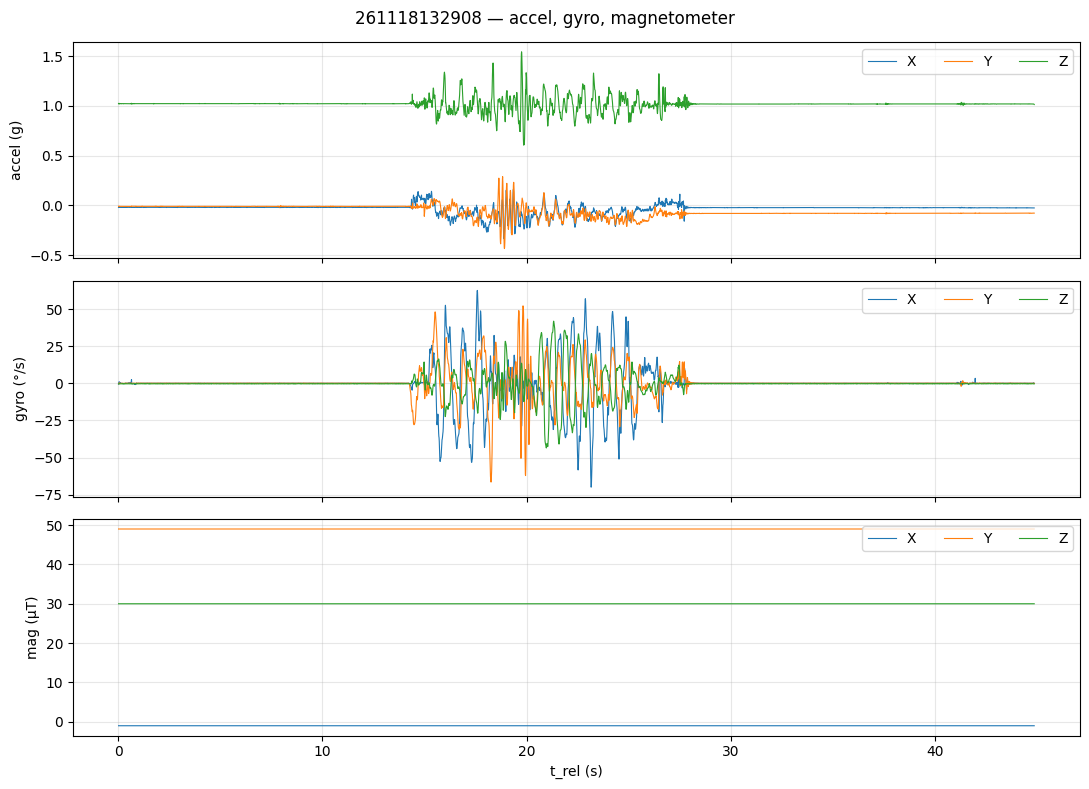

In [41]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
labels = ("X", "Y", "Z")
for i, name in enumerate(labels):
    axes[0].plot(t, acc[:, i], lw=0.8, label=name)
    axes[1].plot(t, gyr[:, i], lw=0.8, label=name)
    axes[2].plot(t, mag[:, i], lw=0.8, label=name)
axes[0].set_ylabel("accel (g)")
axes[1].set_ylabel("gyro (°/s)")
axes[2].set_ylabel("mag (µT)")
axes[2].set_xlabel("t_rel (s)")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", ncol=3)
fig.suptitle("261118132908 — accel, gyro, magnetometer")
fig.tight_layout()
plt.show()


## 3. Empat kombinasi sikap

In [42]:
COMBOS = (
    ("Madgwick 6", "madgwick", 6),
    ("EKF 6", "ekf", 6),
    ("Madgwick 9", "madgwick", 9),
    ("EKF 9", "ekf", 9),
)
COLORS = {
    "Madgwick 6": "#059669",
    "EKF 6": "#0284c7",
    "Madgwick 9": "#d97706",
    "EKF 9": "#e11d48",
}
rpy = {}
for label, method, axes_n in COMBOS:
    rpy[label] = attitude_rpy_deg(t, acc, gyr, mag, method=method, axes=axes_n)

summary = []
for label, angles in rpy.items():
    for i, name in enumerate(("roll", "pitch", "yaw")):
        summary.append({
            "kombinasi": label,
            "sudut": name,
            "mean": angles[:, i].mean(),
            "std": angles[:, i].std(),
            "min": angles[:, i].min(),
            "max": angles[:, i].max(),
            "akhir": angles[-1, i],
        })
pd.DataFrame(summary).round(2)


,kombinasi,sudut,mean,std,min,max,akhir
0,Madgwick 6,roll,-3.21,2.61,-13.04,4.65,-4.34
1,Madgwick 6,pitch,-1.98,2.38,-14.69,5.82,-1.41
2,Madgwick 6,yaw,3.18,1.79,-1.91,7.94,6.70
3,EKF 6,roll,-3.08,2.64,-12.93,4.99,-4.21
4,EKF 6,pitch,-2.12,2.44,-14.82,5.63,-1.42
5,EKF 6,yaw,3.47,1.92,-2.65,7.18,7.18
6,Madgwick 9,roll,-3.18,2.60,-12.74,4.61,-4.34
7,Madgwick 9,pitch,-1.96,2.26,-13.86,5.37,-1.40
8,Madgwick 9,yaw,90.16,1.18,84.12,94.03,90.41
9,EKF 9,roll,-24.67,2.51,-34.61,-0.50,-25.61


## 4. Roll, pitch, dan yaw

Keempat kurva digambar pada sumbu waktu yang sama. Yaw 9 sumbu berada jauh di atas yaw 6 sumbu karena magnetometer menarik heading, bukan hanya offset kecil.

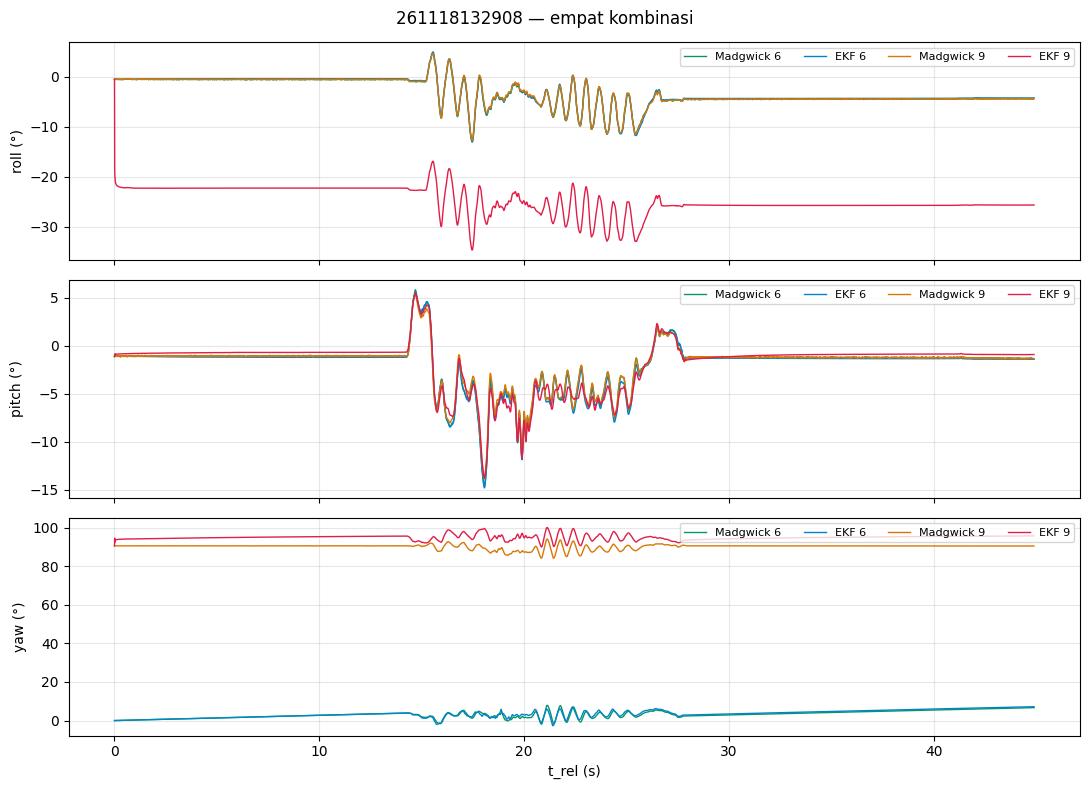

In [43]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, index, name in zip(axes, (0, 1, 2), ("roll", "pitch", "yaw")):
    for label, angles in rpy.items():
        ax.plot(t, angles[:, index], lw=1.0, color=COLORS[label], label=label)
    ax.set_ylabel(f"{name} (°)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", ncol=4, fontsize=8)
axes[-1].set_xlabel("t_rel (s)")
fig.suptitle("261118132908 — empat kombinasi")
fig.tight_layout()
plt.show()


## 5. Selisih terhadap Madgwick 6

Acuan adalah Madgwick 6 sumbu, kombinasi yang dipakai notebook komparasi terhadap 3DM. Selisih yaw dilipat ke −180…180 agar lompatan lingkaran tidak dihitung sebagai ratusan derajat.

Bacaannya: mean adalah offset rata-rata, MAE adalah besar selisih, korelasi membandingkan bentuk setelah offset diabaikan.

In [44]:
def wrap_deg(delta):
    return (delta + 180.0) % 360.0 - 180.0

ref = rpy["Madgwick 6"]
rows = []
for label, angles in rpy.items():
    if label == "Madgwick 6":
        continue
    for i, name in enumerate(("roll", "pitch", "yaw")):
        delta = angles[:, i] - ref[:, i]
        if name == "yaw":
            delta = wrap_deg(delta)
        rows.append({
            "dibanding": label,
            "sudut": name,
            "offset_mean_deg": delta.mean(),
            "MAE_deg": np.mean(np.abs(delta)),
            "korelasi": np.corrcoef(angles[:, i], ref[:, i])[0, 1],
        })
compare = pd.DataFrame(rows).round(3)
compare


,dibanding,sudut,offset_mean_deg,MAE_deg,korelasi
0,EKF 6,roll,0.125,0.162,0.999
1,EKF 6,pitch,-0.135,0.143,0.999
2,EKF 6,yaw,0.283,0.442,0.959
3,Madgwick 9,roll,0.031,0.048,0.999
4,Madgwick 9,pitch,0.029,0.083,0.998
5,Madgwick 9,yaw,86.978,86.978,0.472
6,EKF 9,roll,-21.464,21.464,0.988
7,EKF 9,pitch,0.148,0.409,0.981
8,EKF 9,yaw,91.710,91.710,0.591


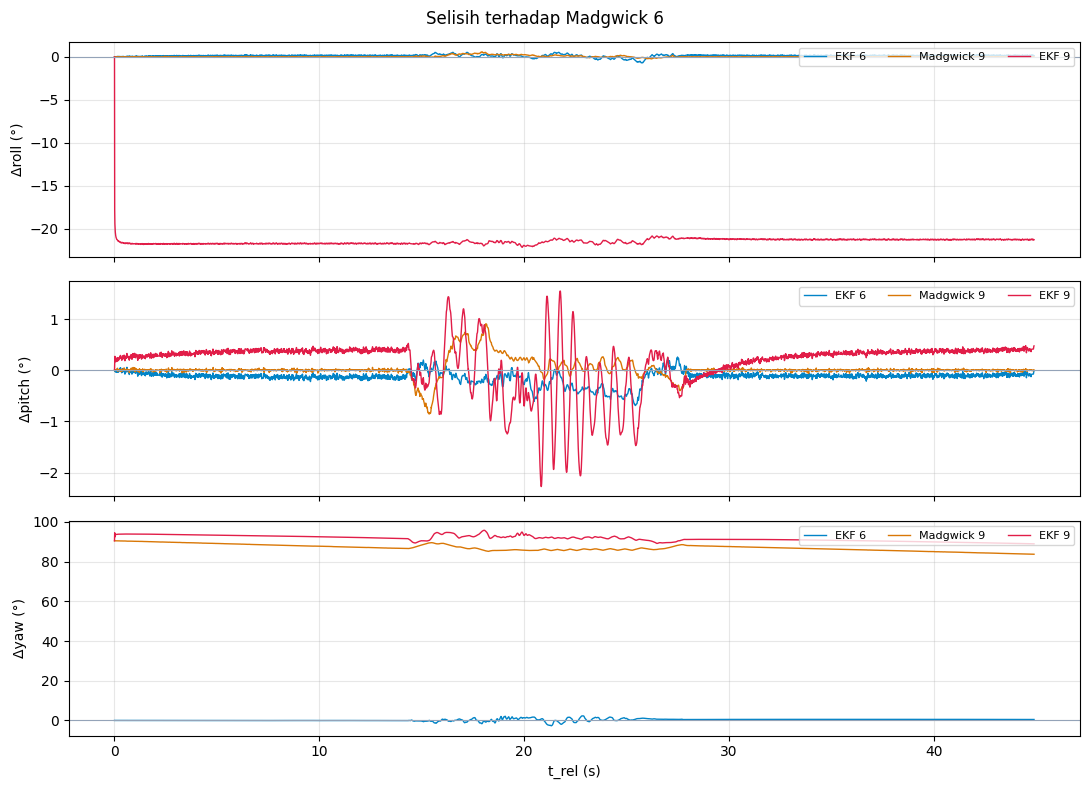

In [45]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, index, name in zip(axes, (0, 1, 2), ("roll", "pitch", "yaw")):
    for label, angles in rpy.items():
        if label == "Madgwick 6":
            continue
        delta = angles[:, index] - ref[:, index]
        if name == "yaw":
            delta = wrap_deg(delta)
        ax.plot(t, delta, lw=1.0, color=COLORS[label], label=label)
    ax.axhline(0, color="#94a3b8", lw=0.8)
    ax.set_ylabel(f"Δ{name} (°)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", ncol=3, fontsize=8)
axes[-1].set_xlabel("t_rel (s)")
fig.suptitle("Selisih terhadap Madgwick 6")
fig.tight_layout()
plt.show()


## 6. Bentuk yaw, offset rata-rata dihilangkan

Korelasi yaw 9 sumbu terhadap Madgwick 6 hanya sekitar 0,5. Plot ini menghilangkan offset rata-rata masing-masing kurva supaya beda bentuknya kelihatan, terpisah dari heading.

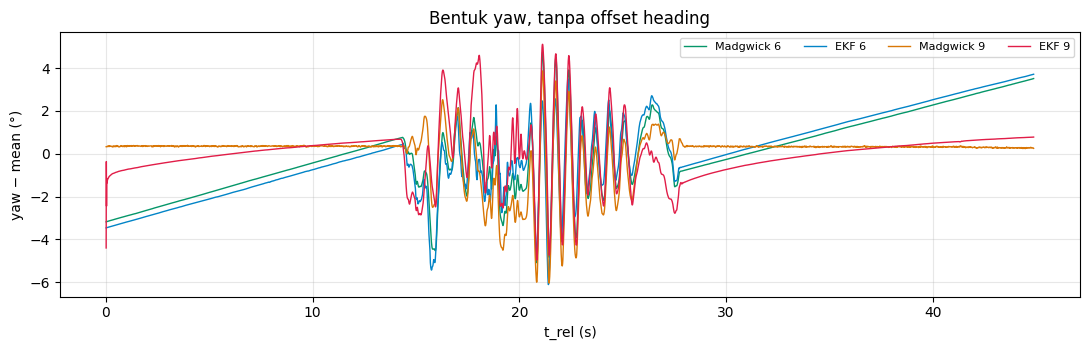

In [46]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for label, angles in rpy.items():
    yaw = angles[:, 2]
    ax.plot(t, yaw - yaw.mean(), lw=1.0, color=COLORS[label], label=label)
ax.set_ylabel("yaw − mean (°)")
ax.set_xlabel("t_rel (s)")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", ncol=4, fontsize=8)
ax.set_title("Bentuk yaw, tanpa offset heading")
fig.tight_layout()
plt.show()


roll: MAE 0.048°   korelasi 0.999


,seri,mean,std,min,max
0,Madgwick 6,-3.209,2.606,-13.045,4.647
1,Madgwick 9,-3.178,2.597,-12.738,4.609
2,9 − 6,0.031,0.099,-0.238,0.584


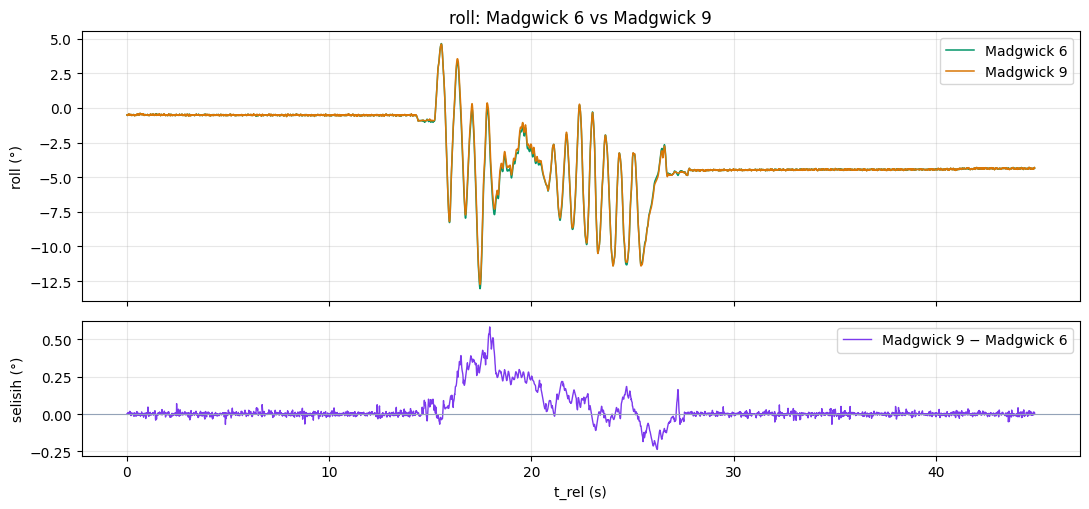

In [47]:
index = 0
name = "roll"
a = rpy["Madgwick 6"][:, index]
b = rpy["Madgwick 9"][:, index]
delta = b - a
if name == "yaw":
    delta = wrap_deg(delta)
stats = pd.DataFrame(
    [
        {"seri": "Madgwick 6", "mean": a.mean(), "std": a.std(), "min": a.min(), "max": a.max()},
        {"seri": "Madgwick 9", "mean": b.mean(), "std": b.std(), "min": b.min(), "max": b.max()},
        {"seri": "9 − 6", "mean": delta.mean(), "std": delta.std(), "min": delta.min(), "max": delta.max()},
    ]
).round(3)
print(
    f"{name}: MAE {np.mean(np.abs(delta)):.3f}°   "
    f"korelasi {np.corrcoef(a, b)[0, 1]:.3f}"
)
display(stats)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, height_ratios=(2, 1))
axes[0].plot(t, a, color=COLORS["Madgwick 6"], lw=1.1, label="Madgwick 6")
axes[0].plot(t, b, color=COLORS["Madgwick 9"], lw=1.1, label="Madgwick 9")
axes[0].set_ylabel(f"{name} (°)")
axes[0].set_title(f"{name}: Madgwick 6 vs Madgwick 9")
axes[0].legend(loc="upper right")
axes[1].plot(t, delta, color="#7c3aed", lw=1.0, label="Madgwick 9 − Madgwick 6")
axes[1].axhline(0, color="#94a3b8", lw=0.8)
axes[1].set_ylabel("selisih (°)")
axes[1].set_xlabel("t_rel (s)")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


pitch: MAE 0.083°   korelasi 0.998


,seri,mean,std,min,max
0,Madgwick 6,-1.984,2.382,-14.695,5.818
1,Madgwick 9,-1.955,2.256,-13.863,5.371
2,9 − 6,0.029,0.182,-0.856,0.909


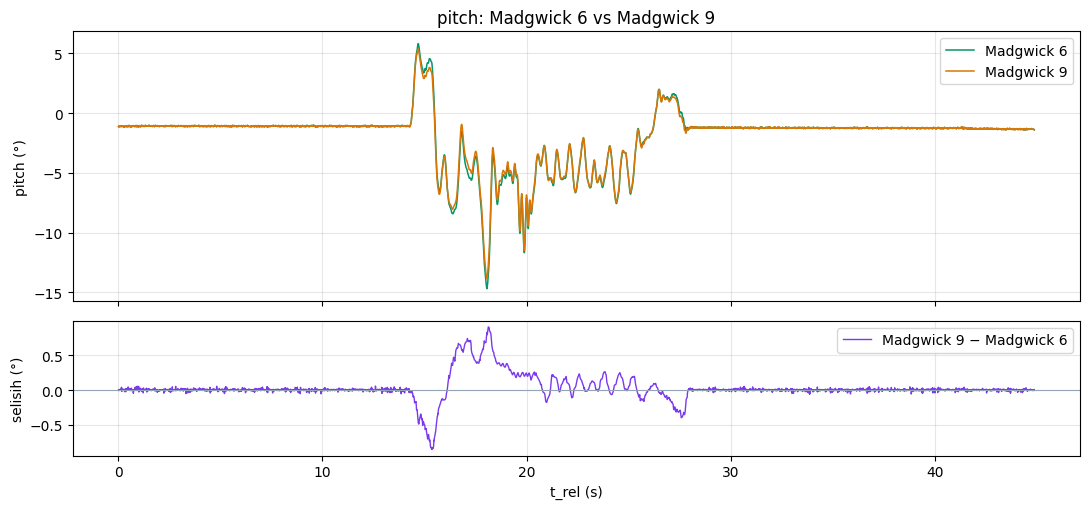

In [48]:
index = 1
name = "pitch"
a = rpy["Madgwick 6"][:, index]
b = rpy["Madgwick 9"][:, index]
delta = b - a
if name == "yaw":
    delta = wrap_deg(delta)
stats = pd.DataFrame(
    [
        {"seri": "Madgwick 6", "mean": a.mean(), "std": a.std(), "min": a.min(), "max": a.max()},
        {"seri": "Madgwick 9", "mean": b.mean(), "std": b.std(), "min": b.min(), "max": b.max()},
        {"seri": "9 − 6", "mean": delta.mean(), "std": delta.std(), "min": delta.min(), "max": delta.max()},
    ]
).round(3)
print(
    f"{name}: MAE {np.mean(np.abs(delta)):.3f}°   "
    f"korelasi {np.corrcoef(a, b)[0, 1]:.3f}"
)
display(stats)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, height_ratios=(2, 1))
axes[0].plot(t, a, color=COLORS["Madgwick 6"], lw=1.1, label="Madgwick 6")
axes[0].plot(t, b, color=COLORS["Madgwick 9"], lw=1.1, label="Madgwick 9")
axes[0].set_ylabel(f"{name} (°)")
axes[0].set_title(f"{name}: Madgwick 6 vs Madgwick 9")
axes[0].legend(loc="upper right")
axes[1].plot(t, delta, color="#7c3aed", lw=1.0, label="Madgwick 9 − Madgwick 6")
axes[1].axhline(0, color="#94a3b8", lw=0.8)
axes[1].set_ylabel("selisih (°)")
axes[1].set_xlabel("t_rel (s)")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


yaw: MAE 86.978°   korelasi 0.472


,seri,mean,std,min,max
0,Madgwick 6,3.184,1.787,-1.908,7.938
1,Madgwick 9,90.162,1.176,84.116,94.030
2,9 − 6,86.978,1.610,83.718,90.493


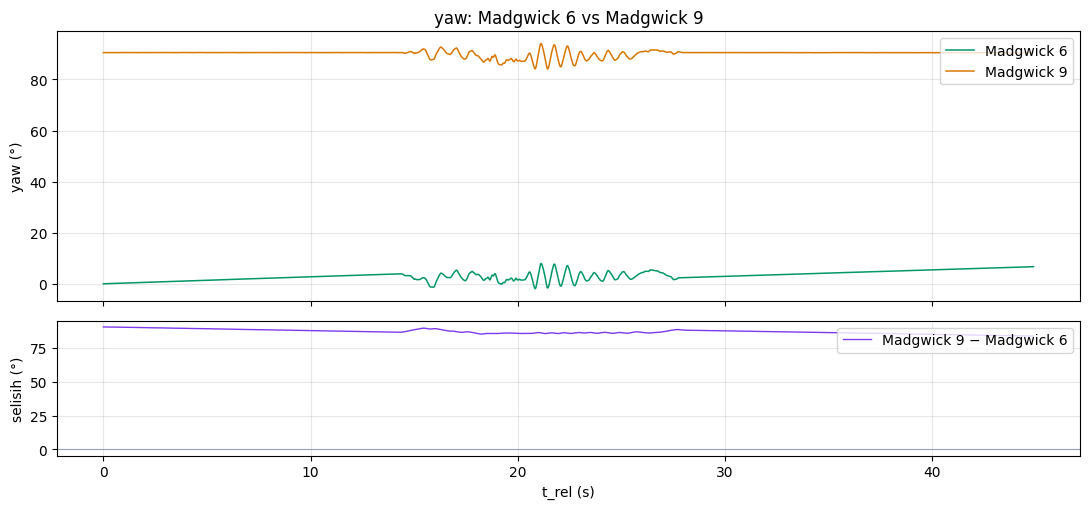

In [49]:
index = 2
name = "yaw"
a = rpy["Madgwick 6"][:, index]
b = rpy["Madgwick 9"][:, index]
delta = b - a
if name == "yaw":
    delta = wrap_deg(delta)
stats = pd.DataFrame(
    [
        {"seri": "Madgwick 6", "mean": a.mean(), "std": a.std(), "min": a.min(), "max": a.max()},
        {"seri": "Madgwick 9", "mean": b.mean(), "std": b.std(), "min": b.min(), "max": b.max()},
        {"seri": "9 − 6", "mean": delta.mean(), "std": delta.std(), "min": delta.min(), "max": delta.max()},
    ]
).round(3)
print(
    f"{name}: MAE {np.mean(np.abs(delta)):.3f}°   "
    f"korelasi {np.corrcoef(a, b)[0, 1]:.3f}"
)
display(stats)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, height_ratios=(2, 1))
axes[0].plot(t, a, color=COLORS["Madgwick 6"], lw=1.1, label="Madgwick 6")
axes[0].plot(t, b, color=COLORS["Madgwick 9"], lw=1.1, label="Madgwick 9")
axes[0].set_ylabel(f"{name} (°)")
axes[0].set_title(f"{name}: Madgwick 6 vs Madgwick 9")
axes[0].legend(loc="upper right")
axes[1].plot(t, delta, color="#7c3aed", lw=1.0, label="Madgwick 9 − Madgwick 6")
axes[1].axhline(0, color="#94a3b8", lw=0.8)
axes[1].set_ylabel("selisih (°)")
axes[1].set_xlabel("t_rel (s)")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## 7. Yaw Madgwick 6 setelah gradien drift dihilangkan

Gradien diambil dari segmen diam pertama: besar gyro di bawah 1,5 °/s. Yaw Madgwick 6 dikurangi `gradien × (t − t0)`. Lalu rata-rata masing-masing kurva dihilangkan supaya bentuknya bisa dibandingkan dengan yaw Madgwick 9, tanpa offset heading sekitar 90°.

Segmen diam 0.7–14.3 s. Gradien 0.2752 °/s (16.51 °/menit). Gyro Z rata-rata -0.266 °/s.
Mentah: MAE 86.978°  korelasi 0.472
Setelah gradien dihilangkan, bentuk tanpa rata-rata: MAE 2.267°  korelasi 0.305


,seri,mean,std,min,max
0,Madgwick 6 mentah,3.184,1.787,-1.908,7.938
1,Madgwick 6 tanpa gradien,-2.988,2.499,-7.640,2.129
2,Madgwick 9,90.162,1.176,84.116,94.030
3,bentuk 9 − bentuk 6,0.000,2.416,-2.957,3.035


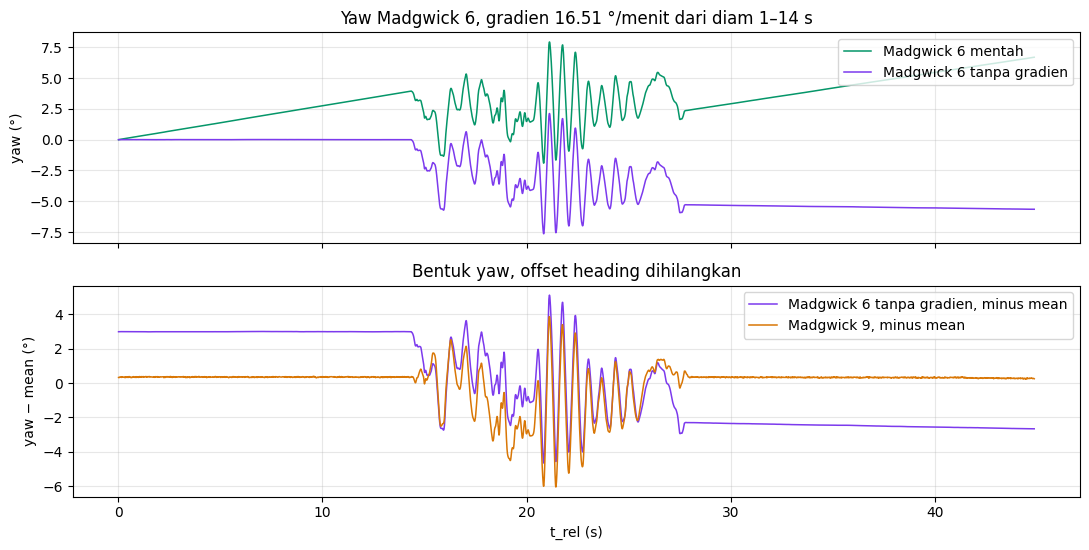

In [50]:
yaw6 = rpy["Madgwick 6"][:, 2]
yaw9 = rpy["Madgwick 9"][:, 2]
rate = np.linalg.norm(gyr, axis=1)
still = rate < 1.5
start = None
first = None
for i, on in enumerate(still):
    if on and start is None:
        start = i
    elif not on and start is not None:
        if t[i - 1] - t[start] >= 3.0:
            first = (start, i)
            break
        start = None
if first is None and start is not None:
    first = (start, len(t))
a, b = first
slope = float(np.polyfit(t[a:b], yaw6[a:b], 1)[0])
yaw6_flat = yaw6 - slope * (t - t[0])
shape6 = yaw6_flat - yaw6_flat.mean()
shape9 = yaw9 - yaw9.mean()
delta_shape = shape9 - shape6

raw_delta = wrap_deg(yaw9 - yaw6)
rows = pd.DataFrame(
    [
        {
            "seri": "Madgwick 6 mentah",
            "mean": yaw6.mean(),
            "std": yaw6.std(),
            "min": yaw6.min(),
            "max": yaw6.max(),
        },
        {
            "seri": "Madgwick 6 tanpa gradien",
            "mean": yaw6_flat.mean(),
            "std": yaw6_flat.std(),
            "min": yaw6_flat.min(),
            "max": yaw6_flat.max(),
        },
        {
            "seri": "Madgwick 9",
            "mean": yaw9.mean(),
            "std": yaw9.std(),
            "min": yaw9.min(),
            "max": yaw9.max(),
        },
        {
            "seri": "bentuk 9 − bentuk 6",
            "mean": delta_shape.mean(),
            "std": delta_shape.std(),
            "min": delta_shape.min(),
            "max": delta_shape.max(),
        },
    ]
).round(3)
print(
    f"Segmen diam {t[a]:.1f}–{t[b - 1]:.1f} s. "
    f"Gradien {slope:.4f} °/s ({slope * 60:.2f} °/menit). "
    f"Gyro Z rata-rata {gyr[a:b, 2].mean():.3f} °/s."
)
print(
    f"Mentah: MAE {np.mean(np.abs(raw_delta)):.3f}°  "
    f"korelasi {np.corrcoef(yaw6, yaw9)[0, 1]:.3f}"
)
print(
    f"Setelah gradien dihilangkan, bentuk tanpa rata-rata: "
    f"MAE {np.mean(np.abs(delta_shape)):.3f}°  "
    f"korelasi {np.corrcoef(shape6, shape9)[0, 1]:.3f}"
)
display(rows)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
axes[0].plot(t, yaw6, color=COLORS["Madgwick 6"], lw=1.1, label="Madgwick 6 mentah")
axes[0].plot(t, yaw6_flat, color="#7c3aed", lw=1.1, label="Madgwick 6 tanpa gradien")
axes[0].set_ylabel("yaw (°)")
axes[0].set_title(
    f"Yaw Madgwick 6, gradien {slope * 60:.2f} °/menit dari diam {t[a]:.0f}–{t[b - 1]:.0f} s"
)
axes[0].legend(loc="upper right")
axes[1].plot(t, shape6, color="#7c3aed", lw=1.1, label="Madgwick 6 tanpa gradien, minus mean")
axes[1].plot(t, shape9, color=COLORS["Madgwick 9"], lw=1.1, label="Madgwick 9, minus mean")
axes[1].set_ylabel("yaw − mean (°)")
axes[1].set_xlabel("t_rel (s)")
axes[1].set_title("Bentuk yaw, offset heading dihilangkan")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## 8. Yaw Madgwick 6: bias gyro dikurangi, yaw ditahan saat diam

Bias tiga sumbu adalah rata-rata gyro pada jendela diam yang baru selesai (minimal 1 s, `|gyro|` di bawah 1,5 °/s, accel dekat 1 g). Gyro rekaman dikurangi bias itu sebelum Madgwick. Selama sampel masih diam, gyro yang masuk filter dibuat nol sehingga yaw tidak berjalan. Mean hanya dipakai di panel bawah untuk menumpuk bentuk dengan Madgwick 9.

Roll/pitch terhadap Madgwick 6 mentah: MAE roll 0.068°  MAE pitch 0.053°
Bentuk yaw terhadap Madgwick 9, mean dihilangkan: MAE 2.199°  korelasi 0.322
diam awal: perubahan yaw 0.001°  (0.00 °/menit)
diam akhir: perubahan yaw -0.001°  (-0.01 °/menit)


,mulai_s,selesai_s,bias_x,bias_y,bias_z
0,0.654,14.268,0.091,0.080,-0.266
1,27.978,41.269,0.103,0.086,-0.240
2,41.992,44.873,0.091,0.075,-0.240


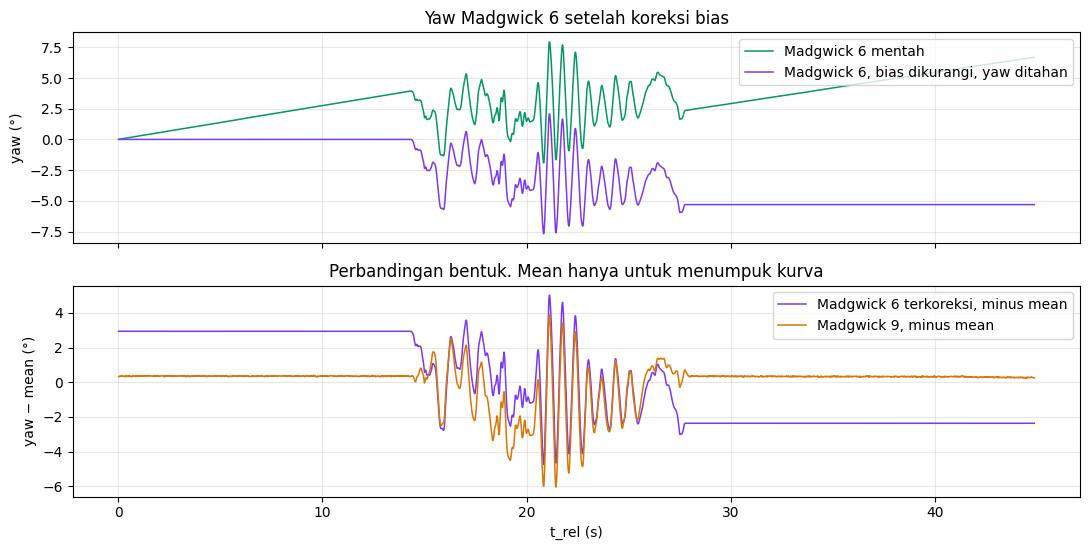

In [51]:
from ahrs.common.orientation import acc2q
from ahrs.filters import Madgwick
from scipy.spatial.transform import Rotation

AXIS = np.array([1.0, -1.0, -1.0])
G_ACC = 9.80665
rate = np.linalg.norm(gyr, axis=1)
amag = np.linalg.norm(acc, axis=1)
still = (rate < 1.5) & (amag > 0.85) & (amag < 1.15)

bias = np.zeros(3)
bias_rows = []
seg_start = None
gyr_use = np.zeros_like(gyr)
for i, on in enumerate(still):
    if on and seg_start is None:
        seg_start = i
    if not on and seg_start is not None:
        if t[i - 1] - t[seg_start] >= 1.0:
            bias = gyr[seg_start:i].mean(axis=0)
            bias_rows.append({
                "mulai_s": t[seg_start],
                "selesai_s": t[i - 1],
                "bias_x": bias[0],
                "bias_y": bias[1],
                "bias_z": bias[2],
            })
        seg_start = None
    gyr_use[i] = 0.0 if on else gyr[i] - bias
if seg_start is not None and t[-1] - t[seg_start] >= 1.0:
    bias_end = gyr[seg_start:].mean(axis=0)
    bias_rows.append({
        "mulai_s": t[seg_start],
        "selesai_s": t[-1],
        "bias_x": bias_end[0],
        "bias_y": bias_end[1],
        "bias_z": bias_end[2],
    })

dt = np.diff(t)
dt = dt[dt > 0]
freq = 1.0 / float(np.median(dt))
acc_ms2 = -(acc * AXIS) * G_ACC
gyr_rad = np.deg2rad(gyr_use) * AXIS
filt = Madgwick(frequency=freq)
quat = np.zeros((len(t), 4))
quat[0] = acc2q(acc_ms2[0])
for i in range(1, len(t)):
    quat[i] = filt.updateIMU(quat[i - 1], gyr_rad[i], acc_ms2[i])
q_xyzw = np.column_stack([quat[:, 1], quat[:, 2], quat[:, 3], quat[:, 0]])
euler = Rotation.from_quat(q_xyzw).as_euler("ZYX", degrees=True)
yaw_hold = euler[:, 0]
roll_hold = euler[:, 2]
pitch_hold = euler[:, 1]

yaw6 = rpy["Madgwick 6"][:, 2]
yaw9 = rpy["Madgwick 9"][:, 2]
shape_hold = yaw_hold - yaw_hold.mean()
shape9 = yaw9 - yaw9.mean()

print(
    f"Roll/pitch terhadap Madgwick 6 mentah: "
    f"MAE roll {np.mean(np.abs(roll_hold - rpy['Madgwick 6'][:, 0])):.3f}°  "
    f"MAE pitch {np.mean(np.abs(pitch_hold - rpy['Madgwick 6'][:, 1])):.3f}°"
)
print(
    f"Bentuk yaw terhadap Madgwick 9, mean dihilangkan: "
    f"MAE {np.mean(np.abs(shape9 - shape_hold)):.3f}°  "
    f"korelasi {np.corrcoef(shape_hold, shape9)[0, 1]:.3f}"
)
for lo, hi, label in ((0.7, 14.3, "diam awal"), (28.0, 41.3, "diam akhir")):
    m = (t >= lo) & (t <= hi)
    dur = float(t[m][-1] - t[m][0])
    slope = float(yaw_hold[m][-1] - yaw_hold[m][0]) / dur * 60.0
    print(f"{label}: perubahan yaw {yaw_hold[m][-1] - yaw_hold[m][0]:.3f}°  ({slope:.2f} °/menit)")
display(pd.DataFrame(bias_rows).round(3))

fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
axes[0].plot(t, yaw6, color=COLORS["Madgwick 6"], lw=1.1, label="Madgwick 6 mentah")
axes[0].plot(t, yaw_hold, color="#7c3aed", lw=1.1, label="Madgwick 6, bias dikurangi, yaw ditahan")
axes[0].set_ylabel("yaw (°)")
axes[0].set_title("Yaw Madgwick 6 setelah koreksi bias")
axes[0].legend(loc="upper right")
axes[1].plot(t, shape_hold, color="#7c3aed", lw=1.1, label="Madgwick 6 terkoreksi, minus mean")
axes[1].plot(t, shape9, color=COLORS["Madgwick 9"], lw=1.1, label="Madgwick 9, minus mean")
axes[1].set_ylabel("yaw − mean (°)")
axes[1].set_xlabel("t_rel (s)")
axes[1].set_title("Perbandingan bentuk. Mean hanya untuk menumpuk kurva")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## Catatan

- Madgwick 6 dan EKF 6 hampir sama. Roll dan pitch selisihnya di bawah 0,2°, korelasi 0,999. Yaw selisih rata-rata di bawah 0,5°.
- Madgwick 9 tidak menggeser roll dan pitch (MAE di bawah 0,1° terhadap Madgwick 6). Yaw-nya bergeser sekitar +87° dan bentuknya tidak mengikuti yaw 6 sumbu (korelasi 0,47).
- EKF 9 menggeser roll sekitar −21° sepanjang rekaman, sementara bentuk roll tetap mirip (korelasi 0,99). Pitch tetap dekat. Yaw bergeser sekitar +92° dengan korelasi 0,59.
- Magnetometer pada berkas ini belum dikalibrasi. Untuk sikap, Madgwick 6 atau EKF 6 adalah pasangan yang saling menguatkan. EKF 9 pada data mag mentah menggeser roll dan tidak layak dipakai sebagai heading.